# RTA Cost Optimization Analysis

## Objective
This notebook compares a traditional high-frequency Rs monitor strategy with an optimized two-tier monitoring strategy for RTA toolsets.

The goal is to evaluate annual monitoring cost, maintenance cost, and failure risk cost, and estimate total annual savings.

In [3]:
from math import ceil
import pandas as pd
import matplotlib.pyplot as plt

In [4]:
## Create the Functions


DAYS_PER_YEAR = 365

def annual_runs(frequency_days):
    return ceil(DAYS_PER_YEAR / frequency_days)

def annual_monitor_cost(cost_per_run, frequency_days):
    return annual_runs(frequency_days) * cost_per_run

def annual_pm_cost(pm_cost_per_event, pm_interval_days):
    return annual_runs(pm_interval_days) * pm_cost_per_event

def annual_failure_cost(expected_failure_events_per_year, failure_cost_per_event):
    return expected_failure_events_per_year * failure_cost_per_event

def total_annual_cost(
    monitor_cost,
    pm_cost,
    failure_cost,
    engineering_overhead=0
):
    return monitor_cost + pm_cost + failure_cost + engineering_overhead

In [5]:
## Baseline Strategy


baseline_monitor = annual_monitor_cost(cost_per_run=5000, frequency_days=7)
baseline_pm = annual_pm_cost(pm_cost_per_event=12000, pm_interval_days=14)
baseline_failure = annual_failure_cost(expected_failure_events_per_year=1.2, failure_cost_per_event=80000)
baseline_total = total_annual_cost(
    monitor_cost=baseline_monitor,
    pm_cost=baseline_pm,
    failure_cost=baseline_failure,
    engineering_overhead=10000
)

baseline = {
    "Strategy": "Baseline - Weekly Rs Monitor",
    "Monitoring Cost": baseline_monitor,
    "PM Cost": baseline_pm,
    "Failure Cost": baseline_failure,
    "Engineering Overhead": 10000,
    "Total Cost": baseline_total
}

baseline

{'Strategy': 'Baseline - Weekly Rs Monitor',
 'Monitoring Cost': 265000,
 'PM Cost': 324000,
 'Failure Cost': 96000.0,
 'Engineering Overhead': 10000,
 'Total Cost': 695000.0}

In [6]:
## Optimized Strategy

optimized_monitor_haze = annual_monitor_cost(cost_per_run=250, frequency_days=3)
optimized_monitor_rs = annual_monitor_cost(cost_per_run=5000, frequency_days=30)
optimized_monitor = optimized_monitor_haze + optimized_monitor_rs

optimized_pm = annual_pm_cost(pm_cost_per_event=12000, pm_interval_days=14)
optimized_failure = annual_failure_cost(expected_failure_events_per_year=0.8, failure_cost_per_event=80000)
optimized_total = total_annual_cost(
    monitor_cost=optimized_monitor,
    pm_cost=optimized_pm,
    failure_cost=optimized_failure,
    engineering_overhead=12000
)

optimized = {
    "Strategy": "Optimized - Haze Every 3 Days + Monthly Rs",
    "Monitoring Cost": optimized_monitor,
    "PM Cost": optimized_pm,
    "Failure Cost": optimized_failure,
    "Engineering Overhead": 12000,
    "Total Cost": optimized_total
}

optimized

{'Strategy': 'Optimized - Haze Every 3 Days + Monthly Rs',
 'Monitoring Cost': 95500,
 'PM Cost': 324000,
 'Failure Cost': 64000.0,
 'Engineering Overhead': 12000,
 'Total Cost': 495500.0}

In [7]:
## Comparsion of the results

df = pd.DataFrame([baseline, optimized])
df

,Strategy,Monitoring Cost,PM Cost,Failure Cost,Engineering Overhead,Total Cost
0,Baseline - Weekly Rs Monitor,265000,324000,96000.0,10000,695000.0
1,Optimized - Haze Every 3 Days + Monthly Rs,95500,324000,64000.0,12000,495500.0


In [8]:
## Calulcation of Saving

annual_savings = baseline_total - optimized_total
savings_pct = annual_savings / baseline_total * 100

print(f"Baseline Cost: ${baseline_total:,.0f}")
print(f"Optimized Cost: ${optimized_total:,.0f}")
print(f"Annual Savings: ${annual_savings:,.0f}")
print(f"Savings Percentage: {savings_pct:.1f}%")

Baseline Cost: $695,000
Optimized Cost: $495,500
Annual Savings: $199,500
Savings Percentage: 28.7%


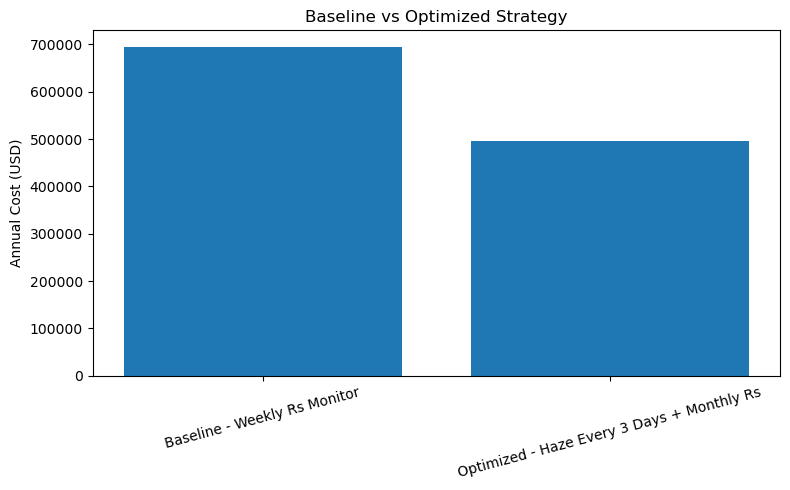

In [9]:
## Graphes of Total Cost Compairsion

plt.figure(figsize=(8,5))
plt.bar(df["Strategy"], df["Total Cost"])
plt.ylabel("Annual Cost (USD)")
plt.title("Baseline vs Optimized Strategy")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

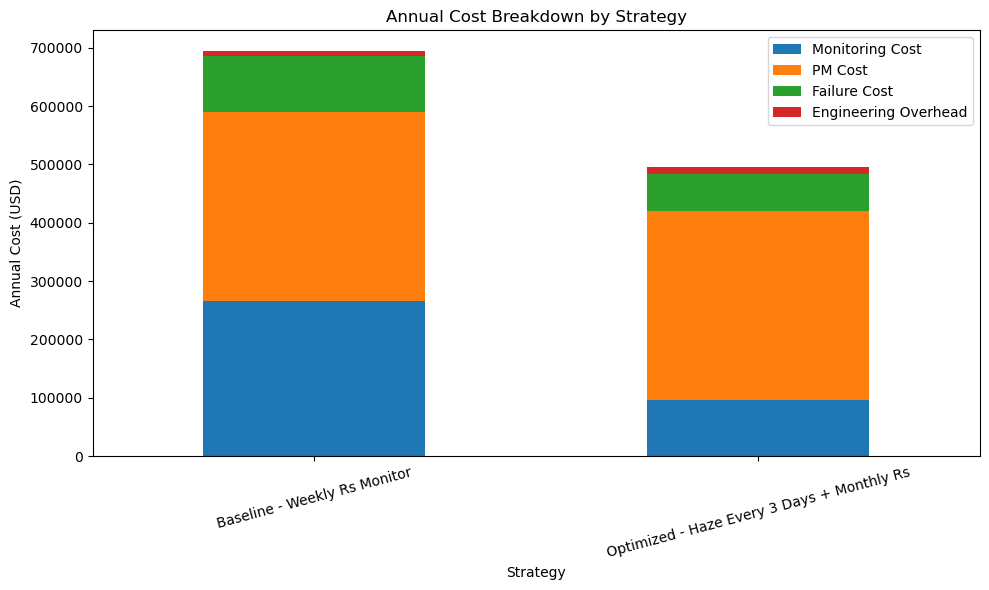

In [10]:
## Graphes of Cost Breakdown

cost_cols = ["Monitoring Cost", "PM Cost", "Failure Cost", "Engineering Overhead"]
plot_df = df.set_index("Strategy")[cost_cols]

plot_df.plot(kind="bar", stacked=True, figsize=(10,6))
plt.ylabel("Annual Cost (USD)")
plt.title("Annual Cost Breakdown by Strategy")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

## Conclusion

The optimized two-tier monitoring strategy reduces dependence on high-cost Rs monitor wafers while maintaining long-term process verification.

Compared with the baseline weekly Rs monitoring strategy, the optimized strategy:
- significantly lowers annual monitoring cost
- improves early drift detection capability
- reduces total annual cost per RTA toolset
- provides a more scalable monitoring framework for advanced semiconductor manufacturing